In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import (
    Dense,
    Flatten,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)

from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)
print("All libraries imported successfully!")

TensorFlow version: 2.21.0
All libraries imported successfully!


In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
project_path = "/content/drive/MyDrive/Down Syndrome ML Project"

dataset_path = os.path.join(
    project_path,
    "down syndrome dataset",
    "Down Syndrome Dataset"
)

train_csv = os.path.join(project_path, "train_split.csv")
val_csv = os.path.join(project_path, "validation_split.csv")
test_csv = os.path.join(project_path, "test_split.csv")

IMG_SIZE = 224
BATCH_SIZE = 32

print("Project path exists:", os.path.exists(project_path))
print("Dataset path exists:", os.path.exists(dataset_path))

print("Training split exists:", os.path.exists(train_csv))
print("Validation split exists:", os.path.exists(val_csv))
print("Testing split exists:", os.path.exists(test_csv))

Project path exists: True
Dataset path exists: True
Training split exists: True
Validation split exists: True
Testing split exists: True


In [6]:
# Load the existing dataset splits

train_df = pd.read_csv(train_csv)
val_df = pd.read_csv(val_csv)
test_df = pd.read_csv(test_csv)

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Testing shape:", test_df.shape)

print("\nTraining distribution:")
print(train_df["label"].value_counts())

print("\nValidation distribution:")
print(val_df["label"].value_counts())

print("\nTesting distribution:")
print(test_df["label"].value_counts())

Training shape: (2099, 2)
Validation shape: (450, 2)
Testing shape: (450, 2)

Training distribution:
label
Down Syndrome    1050
Healthy          1049
Name: count, dtype: int64

Validation distribution:
label
Healthy          225
Down Syndrome    225
Name: count, dtype: int64

Testing distribution:
label
Healthy          225
Down Syndrome    225
Name: count, dtype: int64


In [7]:
# Check dataset overlap

train_paths = set(train_df["filepath"])
val_paths = set(val_df["filepath"])
test_paths = set(test_df["filepath"])

print("Training-validation overlap:", len(train_paths & val_paths))
print("Training-testing overlap:", len(train_paths & test_paths))
print("Validation-testing overlap:", len(val_paths & test_paths))

# Check missing images

all_paths = train_paths | val_paths | test_paths

missing_paths = [
    path for path in all_paths
    if not os.path.exists(path)
]

print("\nTotal image paths:", len(all_paths))
print("Missing image paths:", len(missing_paths))

Training-validation overlap: 0
Training-testing overlap: 0
Validation-testing overlap: 0

Total image paths: 2999
Missing image paths: 0


In [8]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# VGG16 preprocessing
from tensorflow.keras.applications.vgg16 import preprocess_input

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="filepath",
    y_col="label",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=True,
    seed=42
)

validation_generator = val_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col="filepath",
    y_col="label",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="filepath",
    y_col="label",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

Found 2099 validated image filenames belonging to 2 classes.
Found 450 validated image filenames belonging to 2 classes.
Found 450 validated image filenames belonging to 2 classes.


In [9]:
print("Class mapping:", train_generator.class_indices)

images, labels = next(train_generator)

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Minimum pixel value:", images.min())
print("Maximum pixel value:", images.max())

Class mapping: {'Down Syndrome': 0, 'Healthy': 1}

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: -123.68
Maximum pixel value: 151.061


In [10]:
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

print("VGG16 model loaded successfully!")
print("Total layers:", len(base_model.layers))

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VGG16 model loaded successfully!
Total layers: 19


In [11]:
base_model.trainable = False

print("VGG16 base layers frozen.")
print("Total layers:", len(base_model.layers))

print(
    "Trainable layers:",
    sum(layer.trainable for layer in base_model.layers)
)

VGG16 base layers frozen.
Total layers: 19
Trainable layers: 0


In [12]:
from tensorflow.keras.layers import GlobalAveragePooling2D

x = base_model.output

x = GlobalAveragePooling2D()(x)

x = Dense(
    256,
    activation="relu"
)(x)

x = Dropout(0.5)(x)

output = Dense(
    1,
    activation="sigmoid"
)(x)

model = Model(
    inputs=base_model.input,
    outputs=output
)

print("VGG16 classification model created successfully!")

VGG16 classification model created successfully!


In [13]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,846,273 (56.63 MB)

 Trainable params: 131,585 (514.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [14]:
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("VGG16 model compiled successfully!")

VGG16 model compiled successfully!


In [15]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

checkpoint = ModelCheckpoint(
    filepath=os.path.join(project_path, "best_vgg16_model.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

print("Model checkpoint and early stopping configured successfully!")

Model checkpoint and early stopping configured successfully!


In [16]:
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="filepath",
    y_col="label",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=True,
    seed=42
)

print("Training generator updated with data augmentation!")

Found 2099 validated image filenames belonging to 2 classes.
Training generator updated with data augmentation!


In [19]:
history_initial = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=5,
    callbacks=[checkpoint, early_stop]
)

Epoch 1/5
45/66 ━━━━━━━━━━━━━━━━━━━━ 4:17 12s/step - accuracy: 0.5305 - loss: 2.4315

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 12s/step - accuracy: 0.5343 - loss: 2.2026 
Epoch 1: val_loss improved from None to 0.76389, saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_vgg16_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_vgg16_model.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 1002s 15s/step - accuracy: 0.5460 - loss: 1.6511 - val_accuracy: 0.6333 - val_loss: 0.7639
Epoch 2/5
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 503ms/step - accuracy: 0.5924 - loss: 1.1098
Epoch 2: val_loss improved from 0.76389 to 0.62436, saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_vgg16_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_vgg16_model.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 36s 545ms/step - accuracy: 0.6046 - loss: 1.0264 - val_accuracy: 0.6933 - val_loss: 0.6244
Epoch 3/5
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 497ms/step - accuracy: 0.6229 - loss: 0.9371
Epoch 3: val_loss improved from 0

In [20]:
base_model.trainable = True

# Freeze all layers initially
for layer in base_model.layers:
    layer.trainable = False

# Unfreeze the last 4 layers
for layer in base_model.layers[-4:]:
    layer.trainable = True

print("VGG16 fine-tuning configuration:")
print("Total layers:", len(base_model.layers))
print("Trainable layers:", sum(layer.trainable for layer in base_model.layers))

for layer in base_model.layers[-4:]:
    print(layer.name, ":", layer.trainable)

VGG16 fine-tuning configuration:
Total layers: 19
Trainable layers: 4
block5_conv1 : True
block5_conv2 : True
block5_conv3 : True
block5_pool : True


In [21]:
model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("VGG16 model recompiled for fine-tuning!")

VGG16 model recompiled for fine-tuning!


In [22]:
history_finetune = model.fit(
    train_generator,
    validation_data=validation_generator,
    initial_epoch=5,
    epochs=15,
    callbacks=[checkpoint, early_stop]
)

Epoch 6/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 540ms/step - accuracy: 0.7228 - loss: 0.6609
Epoch 6: val_loss improved from 0.53055 to 0.46780, saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_vgg16_model.keras

Epoch 6: finished saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_vgg16_model.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 46s 610ms/step - accuracy: 0.7070 - loss: 0.6227 - val_accuracy: 0.7667 - val_loss: 0.4678
Epoch 7/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 542ms/step - accuracy: 0.7596 - loss: 0.4974
Epoch 7: val_loss improved from 0.46780 to 0.38267, saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_vgg16_model.keras

Epoch 7: finished saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_vgg16_model.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 39s 587ms/step - accuracy: 0.7685 - loss: 0.4877 - val_accuracy: 0.8156 - val_loss: 0.3827
Epoch 8/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 529ms/step - accuracy: 0.8060 - loss: 0.4175
Epoch 8: val_los

In [23]:
# Combine training and fine-tuning histories

acc = history_initial.history["accuracy"] + history_finetune.history["accuracy"]
val_acc = history_initial.history["val_accuracy"] + history_finetune.history["val_accuracy"]

loss = history_initial.history["loss"] + history_finetune.history["loss"]
val_loss = history_initial.history["val_loss"] + history_finetune.history["val_loss"]

print("Total epochs:", len(acc))
print("Training and validation histories combined successfully!")

Total epochs: 15
Training and validation histories combined successfully!


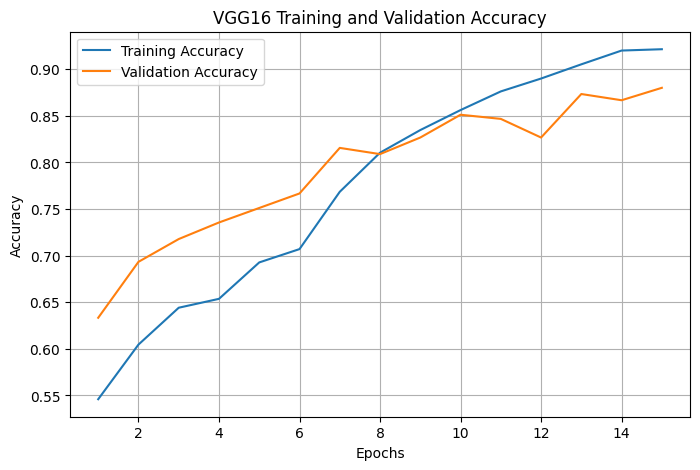

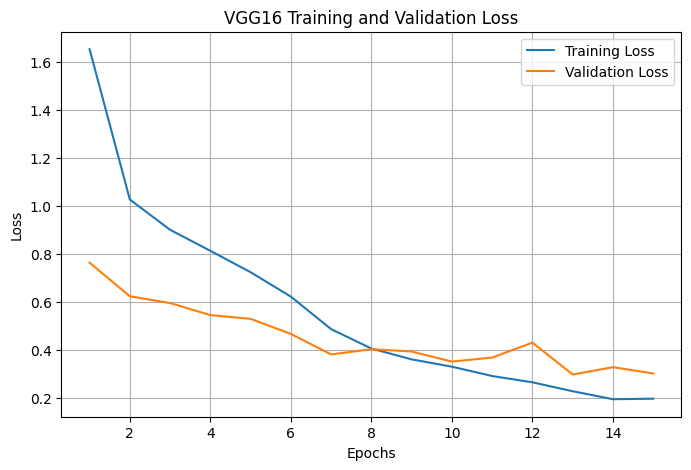

In [24]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(acc) + 1)

# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, acc, label="Training Accuracy")
plt.plot(epochs_range, val_acc, label="Validation Accuracy")
plt.title("VGG16 Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Loss graph
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, loss, label="Training Loss")
plt.plot(epochs_range, val_loss, label="Validation Loss")
plt.title("VGG16 Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [25]:
from tensorflow.keras.models import load_model

best_vgg16_model = load_model(
    os.path.join(project_path, "best_vgg16_model.keras")
)

print("Best VGG16 model loaded successfully!")

Best VGG16 model loaded successfully!


In [26]:
test_loss, test_accuracy = best_vgg16_model.evaluate(test_generator)

print("VGG16 Test Loss:", test_loss)
print("VGG16 Test Accuracy:", test_accuracy * 100, "%")

15/15 ━━━━━━━━━━━━━━━━━━━━ 153s 11s/step - accuracy: 0.8933 - loss: 0.2699
VGG16 Test Loss: 0.26988959312438965
VGG16 Test Accuracy: 89.33333158493042 %


In [27]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# Generate predictions
predictions = best_vgg16_model.predict(test_generator)

# Convert probabilities into class predictions
y_pred = (predictions > 0.5).astype(int).ravel()

# Actual labels
y_true = test_generator.classes

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

print("VGG16 Confusion Matrix:")
print(cm)

# Classification report
print("\nVGG16 Classification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Down Syndrome", "Healthy"]
))

15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 177ms/step
VGG16 Confusion Matrix:
[[212  13]
 [ 35 190]]

VGG16 Classification Report:
               precision    recall  f1-score   support

Down Syndrome       0.86      0.94      0.90       225
      Healthy       0.94      0.84      0.89       225

     accuracy                           0.89       450
    macro avg       0.90      0.89      0.89       450
 weighted avg       0.90      0.89      0.89       450



In [28]:
import pandas as pd

vgg16_results = pd.DataFrame({
    "Model": ["VGG16"],
    "Test Accuracy": [test_accuracy * 100],
    "Test Loss": [test_loss],
    "Precision (DS)": [0.86],
    "Recall (DS)": [0.94],
    "F1-score (DS)": [0.90],
    "Precision (Healthy)": [0.94],
    "Recall (Healthy)": [0.84],
    "F1-score (Healthy)": [0.89]
})

vgg16_results.to_csv(
    os.path.join(project_path, "vgg16_results.csv"),
    index=False
)

print("VGG16 results saved successfully!")

VGG16 results saved successfully!


In [29]:
comparison_df = pd.DataFrame({
    "Model": ["Custom CNN", "ResNet50", "VGG16"],
    "Test Accuracy (%)": [
        80.44,
        89.33,
        89.33
    ],
    "Test Loss": [
        0.4518,
        0.2401,
        0.2699
    ],
    "Correct Predictions": [
        362,
        402,
        402
    ],
    "Incorrect Predictions": [
        88,
        48,
        48
    ]
})

display(comparison_df)

,Model,Test Accuracy (%),Test Loss,Correct Predictions,Incorrect Predictions
0,Custom CNN,80.44,0.4518,362,88
1,ResNet50,89.33,0.2401,402,48
2,VGG16,89.33,0.2699,402,48


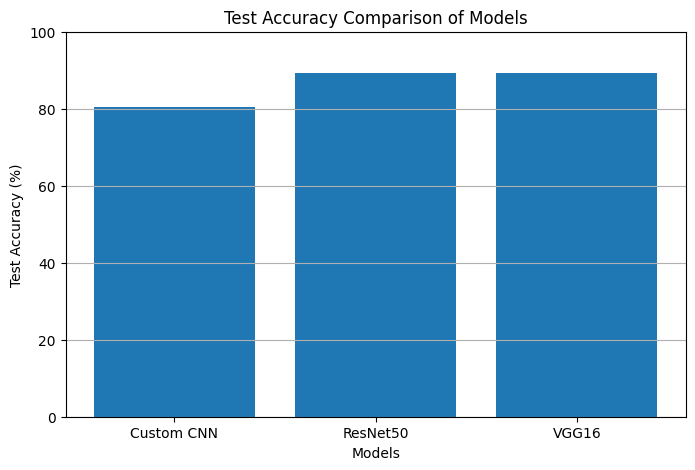

In [30]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Test Accuracy (%)"]
)

plt.title("Test Accuracy Comparison of Models")
plt.xlabel("Models")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)
plt.grid(axis="y")
plt.show()

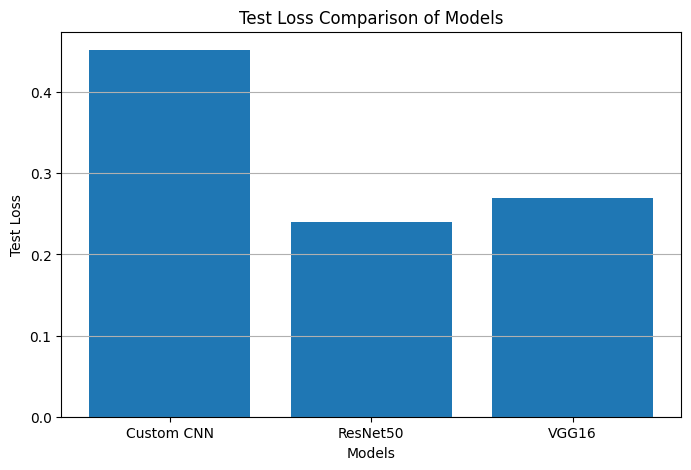

In [31]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Test Loss"]
)

plt.title("Test Loss Comparison of Models")
plt.xlabel("Models")
plt.ylabel("Test Loss")
plt.grid(axis="y")
plt.show()

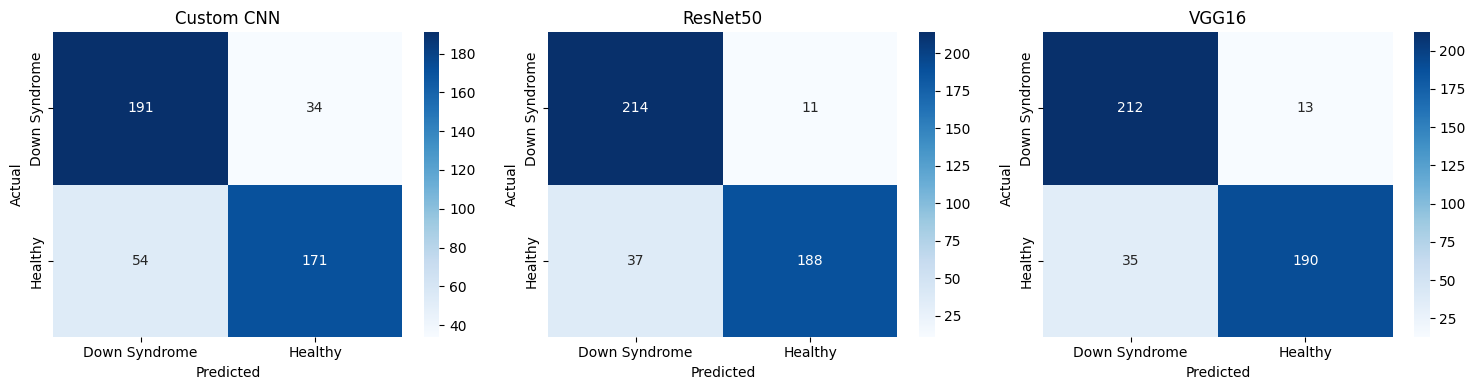

In [32]:
import seaborn as sns

cms = [
    np.array([[191, 34], [54, 171]]),
    np.array([[214, 11], [37, 188]]),
    np.array([[212, 13], [35, 190]])
]

model_names = ["Custom CNN", "ResNet50", "VGG16"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, cm, name in zip(axes, cms, model_names):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Down Syndrome", "Healthy"],
        yticklabels=["Down Syndrome", "Healthy"],
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [33]:
# Add macro F1-scores to the comparison table
comparison_df["Macro F1-score (%)"] = [
    80.41,
    89.30,
    89.50
]

# Save comparison results
comparison_path = os.path.join(
    project_path,
    "model_comparison.csv"
)

comparison_df.to_csv(comparison_path, index=False)

print("Final model comparison saved successfully!")
print("File location:", comparison_path)

display(comparison_df)

Final model comparison saved successfully!
File location: /content/drive/MyDrive/Down Syndrome ML Project/model_comparison.csv


,Model,Test Accuracy (%),Test Loss,Correct Predictions,Incorrect Predictions,Macro F1-score (%)
0,Custom CNN,80.44,0.4518,362,88,80.41
1,ResNet50,89.33,0.2401,402,48,89.30
2,VGG16,89.33,0.2699,402,48,89.50


In [34]:
import os

for item in sorted(os.listdir(project_path)):
    item_path = os.path.join(project_path, item)

    if os.path.isdir(item_path):
        print(f"[FOLDER] {item}")
    else:
        size_mb = os.path.getsize(item_path) / (1024 * 1024)
        print(f"[FILE] {item} — {size_mb:.2f} MB")

[FILE] accuracy_graph.png — 0.16 MB
[FILE] best_cnn_model.keras — 127.87 MB
[FILE] best_cnn_model_resumed.keras — 127.87 MB
[FILE] best_resnet50_model.keras — 206.71 MB
[FILE] best_vgg16_model.keras — 111.74 MB
[FOLDER] down syndrome dataset
[FILE] loss_graph.png — 0.16 MB
[FILE] model_comparison.csv — 0.00 MB
[FILE] test_split.csv — 0.05 MB
[FILE] train_split.csv — 0.26 MB
[FILE] validation_split.csv — 0.05 MB
[FILE] vgg16_results.csv — 0.00 MB
